### UCI Gene Expression Cancer RNA-Seq UMAP 降维

流程：读取数据 → 去掉方差为 0 的基因并标准化 → UMAP 降维 → 保存结果。

`gene-PCA.ipynb` 和 `gene-UMAP.ipynb` 的读取与预处理代码完全相同，两边降维用的是同一个特征矩阵。

数据：801 个样本 × 20531 个基因，5 种肿瘤类型（BRCA 乳腺浸润癌、COAD 结肠腺癌、KIRC 肾透明细胞癌、LUAD 肺腺癌、PRAD 前列腺腺癌），位于 `dataset/TCGA-PANCAN-HiSeq-801x20531/`。

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
import umap

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
N_COMPONENTS = 10   # 降维维数，PCA 和 UMAP 保持一致

C:\Users\luo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### 1. 读取数据

In [2]:
DATA_DIR = Path('dataset') / 'TCGA-PANCAN-HiSeq-801x20531'

# data.csv 约 200MB，第一列是样本名
data = pd.read_csv(DATA_DIR / 'data.csv', index_col=0).astype(np.float32)
labels = pd.read_csv(DATA_DIR / 'labels.csv', index_col=0)['Class']

assert (data.index == labels.index).all() and not data.isna().any().any()
print('data:', data.shape, ' labels:', labels.shape)

data: (801, 20531)  labels: (801,)


#### 2. 预处理

- 去掉在所有样本上方差为 0 的基因（267 个），它们对降维和聚类没有信息量
- 标准化（每个基因均值 0、方差 1）
- 标签编码成整数，只用于聚类后的外部评价指标

In [3]:
data = data.loc[:, data.var(axis=0) > 0]
X = StandardScaler().fit_transform(data.values).astype(np.float32)

le = LabelEncoder()
y = le.fit_transform(labels.values)
CLASS_NAMES = list(le.classes_)

print('X:', X.shape, X.dtype)
print('y:', y.shape, dict(zip(CLASS_NAMES, np.bincount(y).tolist())))

X: (801, 20264) float32
y: (801,) {'BRCA': 300, 'COAD': 78, 'KIRC': 146, 'LUAD': 141, 'PRAD': 136}


#### 3. UMAP 降维

参数按 UMAP 官方文档中用于聚类的建议设置：`min_dist=0.0` 让同类样本聚得更紧，`n_neighbors=30` 更多照顾全局结构。`random_state` 固定后结果可复现（UMAP 会因此改为单线程，速度慢一些）。

降到 `N_COMPONENTS` 维用于聚类。UMAP 高维结果取前 2 列没有意义，所以另外拟合一个 2 维 UMAP 专门画图。

In [4]:
UMAP_PARAMS = dict(n_neighbors=30, min_dist=0.0, metric='euclidean', random_state=SEED, n_jobs=1)

X_red = umap.UMAP(n_components=N_COMPONENTS, **UMAP_PARAMS).fit_transform(X)
X_red_2d = umap.UMAP(n_components=2, **UMAP_PARAMS).fit_transform(X)

print('降维后:', X_red.shape, ' 画图用:', X_red_2d.shape)

降维后: (801, 10)  画图用: (801, 2)


#### 4. 保存结果

结果保存在变量 `gene_umap_redu_result`（字典）中，同时写入 `result/gene-umap-redu-result.npz`。后续聚类直接读文件，不用重跑降维：

```python
r = np.load('result/gene-umap-redu-result.npz')
X, y = r['embedding'], r['labels']
```

| 键 | 内容 |
|---|---|
| `embedding` | (801, N_COMPONENTS) 降维结果，聚类用 |
| `embedding_2d` | (801, 2)，画图用 |
| `labels` | 真实类别（整数），只用于 ARI、NMI 等外部指标，聚类时不能用 |
| `class_names` | 类别名，下标对应 `labels` |
| `sample_ids` | 样本名（sample_0 …），PCA 与 UMAP 两份结果应完全相同 |
| `n_neighbors`、`min_dist` | UMAP 参数 |
| `n_components`、`seed` | 降维维数和随机种子 |

In [5]:
gene_umap_redu_result = {
    'embedding': X_red.astype(np.float32),
    'embedding_2d': X_red_2d.astype(np.float32),
    'labels': y,
    'class_names': np.array(CLASS_NAMES),
    'sample_ids': data.index.to_numpy().astype(str),
    'n_neighbors': UMAP_PARAMS['n_neighbors'],
    'min_dist': UMAP_PARAMS['min_dist'],
    'n_components': N_COMPONENTS,
    'seed': SEED,
}

RESULT_FILE = Path('result') / 'gene-umap-redu-result.npz'
RESULT_FILE.parent.mkdir(exist_ok=True)
np.savez(RESULT_FILE, **gene_umap_redu_result)

# 读回来逐项核对
with np.load(RESULT_FILE) as saved:
    assert all(np.array_equal(saved[k], v) for k, v in gene_umap_redu_result.items())
print('已保存并校验:', RESULT_FILE)
for k, v in gene_umap_redu_result.items():
    print(f'  {k}: shape={np.shape(v)}, dtype={np.asarray(v).dtype}')

已保存并校验: result\gene-umap-redu-result.npz
  embedding: shape=(801, 10), dtype=float32
  embedding_2d: shape=(801, 2), dtype=float32
  labels: shape=(801,), dtype=int64
  class_names: shape=(5,), dtype=<U4
  sample_ids: shape=(801,), dtype=<U10
  n_neighbors: shape=(), dtype=int64
  min_dist: shape=(), dtype=float64
  n_components: shape=(), dtype=int64
  seed: shape=(), dtype=int64


#### 5. 可视化检查

二维结果按真实类别着色，只用来确认降维结果正常。

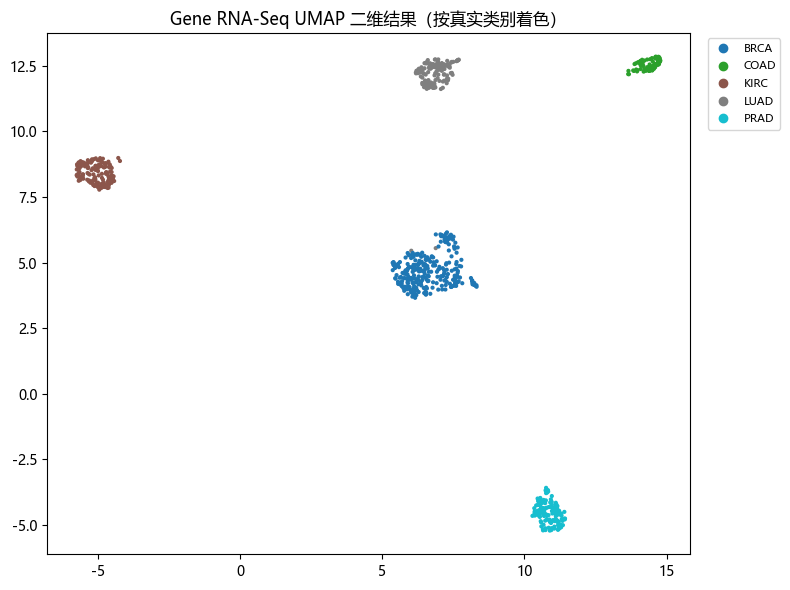

In [6]:
emb2 = gene_umap_redu_result['embedding_2d']
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(emb2[:, 0], emb2[:, 1], c=y, cmap='tab10', s=4)
ax.legend(sc.legend_elements()[0], CLASS_NAMES, fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_title('Gene RNA-Seq UMAP 二维结果（按真实类别着色）')
plt.tight_layout()
plt.show()